### introduction
the way scikit learn works is that you give it data to model and than that model makes a prediction

the dataset can be split up into 2 parts: X, y

X is the data which trains the model

y is the data which test if model makes correct prediction

so X is used to make model learn pattern to make predictions.


In [9]:
from sklearn.datasets import fetch_california_housing
import matplotlib.pyplot as plt
import pandas as pd

In [2]:
X, y = fetch_california_housing(return_X_y=True)
# print(X, y)

when you create a model it does not do anything. 
all models are python objects.
there are 2 phases a model has to go through
1. create -> object
2. learn -> fit(X,y) # this is a method of object which is used to train model to make predictions
afterwards the model is ready to make predictions

In [3]:
from sklearn.neighbors import KNeighborsRegressor
from sklearn.linear_model import LinearRegression

# model assigned to a variable
# this is the create phase

# mod = LinearRegression()
mod = KNeighborsRegressor()

# this is the learn phase
mod.fit(X,y)

# both .fit and .predict are apis
# even if we change the model we can still use the same api to learn and predict models.
# this helps us to stick with apis and not be concerned with internals of a model.
mod.predict(X)

array([2.826802, 2.1594  , 3.650404, ..., 1.2882  , 1.4418  , 1.7342  ],
      shape=(20640,))

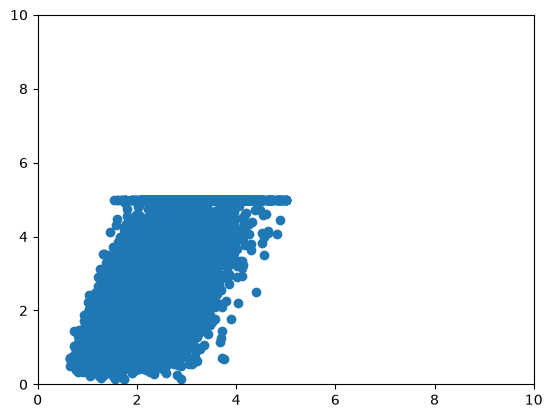

In [4]:
# plotting the predictions on x axis and predicted values on y axis
pred = mod.predict(X)
plt.scatter(pred, y)
# plt.margins(0.2)
plt.xlim(0,10)
plt.ylim(0,10)
plt.show()


the parameters X and y can be in different units, so for that reason we have to ensure that they become same.
so for that reason we scale (preprocess) the X to match the appropriate units of y.

so now our structure becomes
data -> (X, y)
X -> model(scale + KNN) -> pred
y -> model -> pred

now our predictions would be different than before
so now we have a model being =  to scale + KNN
in scikit learn this is called a pipeline

a pipeline is a tool that chains multiple data processing steps and a ML model into a single, cohesive obj

the pipeline also have .fit and .predict apis.
so now this works better as we can just interact with one obj instead of many.

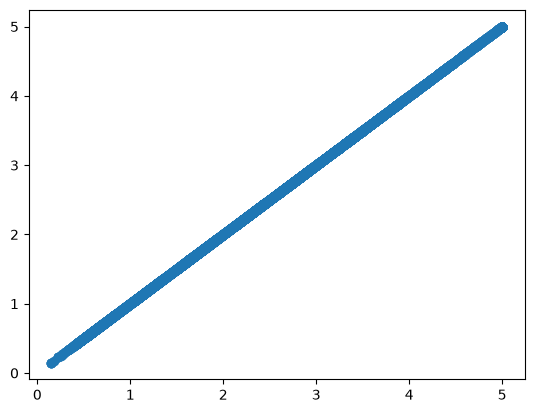

In [7]:
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.model_selection import GridSearchCV

mod = KNeighborsRegressor().fit(X, y)
pipe = Pipeline([
    ("scale", StandardScaler()),     # pass 2nd arg as obj not class, hence we put "()"
    ("model", KNeighborsRegressor(n_neighbors=1))
])
pipe.fit(X,y)
pred = pipe.predict(X)
plt.scatter(pred, y)
plt.show()

GridSearchCV is a tool used for automated hypterparameter tuning. it helps to find the optimal setting for a model by systematically training and evaluating it on every possible combination of values in a defined grid.

cross validation (CV) is a resampling technique used to evaluate how well a model generalizes to unseen data while preventing overfitting.

In [13]:
# tells what parameters our model have
# pipe.get_params()
n_range = [x for x in range(1,21)]
mod = GridSearchCV(estimator=pipe, param_grid={"model__n_neighbors":n_range }, cv=3)
mod.fit(X,y)
pd.DataFrame(mod.cv_results_)

,mean_fit_time,std_fit_time,mean_score_time,std_score_time,param_model__n_neighbors,params,split0_test_score,split1_test_score,split2_test_score,mean_test_score,std_test_score,rank_test_score
0,0.116224,0.065647,0.750485,0.041697,1,{'model__n_neighbors': 1},0.324068,0.334830,0.323371,0.327423,0.005245,20
1,0.051553,0.000794,0.778721,0.144171,2,{'model__n_neighbors': 2},0.468788,0.503457,0.424388,0.465544,0.032361,19
2,0.231595,0.250438,1.808087,0.745676,3,{'model__n_neighbors': 3},0.518547,0.543340,0.473595,0.511827,0.028867,18
3,0.066643,0.013720,1.281009,0.458734,4,{'model__n_neighbors': 4},0.540323,0.564974,0.499827,0.535041,0.026857,17
4,0.058047,0.004193,0.930114,0.181279,5,{'model__n_neighbors': 5},0.551149,0.579313,0.511781,0.547414,0.027696,16
5,0.086418,0.043029,1.992462,0.509365,6,{'model__n_neighbors': 6},0.558435,0.586185,0.521134,0.555251,0.026652,15
6,0.090755,0.021660,1.302384,0.260458,7,{'model__n_neighbors': 7},0.564207,0.590509,0.525223,0.559979,0.026820,14
7,0.067434,0.012215,1.196280,0.066557,8,{'model__n_neighbors': 8},0.568637,0.593942,0.529337,0.563972,0.026580,13
8,0.056328,0.001421,1.035743,0.120454,9,{'model__n_neighbors': 9},0.571972,0.594863,0.529928,0.565588,0.026891,12
9,0.057897,0.007134,1.128477,0.162009,10,{'model__n_neighbors': 10},0.573760,0.595831,0.532973,0.567522,0.026038,11
